# **Social Media Sentiment & Engagement Analysis**

**Domain:** Social Media & Public Sentiment
**Author:** *Mrudula KP*
**Date:** *18-07-2026*

## 1. Problem Statement

Brands and content teams need to understand **what drives engagement** on social
media and **how sentiment varies** across platforms, countries, and time. This
project analyzes a dataset of **2,260 social media posts** spanning 5 platforms
(Twitter, Instagram, Facebook, TikTok, LinkedIn) and 12 countries, collected
between January 2023 and December 2024.


**Guiding questions:**
1. Which platforms and content types generate the most engagement (likes, shares, comments)?
2. How does sentiment (Positive / Negative / Neutral) differ by platform and country?
3. Does account size (followers) or verification status meaningfully affect engagement?
4. Are there time-based patterns (day of week, month, hour) in posting volume or engagement?
5. What relationships exist between engagement metrics themselves?


## 2. Dataset Overview

- **Source file:** `social_media_sentiment_raw.csv` (raw, as collected)
- **Records:** 2,260 rows (before cleaning)
- **Features:** 13 columns — a mix of numerical (`followers_count`, `likes`,
  `retweets_shares`, `comments`) and categorical (`platform`, `country`,
  `verified`, `sentiment`, `hashtags`) data, plus free text and a timestamp.

> **Note on the data:** This dataset was synthetically generated to closely mimic
> real-world social media analytics datasets (e.g., Kaggle's *Social Media
> Sentiments Analysis Dataset*), including realistic messiness — missing values,
> duplicate rows, inconsistent text casing, and a dtype issue in
> `followers_count` — so that the cleaning steps below reflect genuine
> real-world pre-processing work.

# **Dataset**

Records: 2,260 posts (before cleaning)
Platforms: Twitter, Instagram, Facebook, TikTok, LinkedIn
Countries: 12 countries covered
Time range: January 2023 – December 2024
Columns: post_id, timestamp, platform, user, followers_count, verified, text, hashtags, country, likes, retweets_shares, comments, sentiment

# **Tools & Libraries**

Python
Pandas, NumPy — data cleaning and manipulation
Matplotlib, Seaborn — visualizations
Google Colab / Jupyter Notebook

**Source data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


**Import Libraries & Setup**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)

**Loading the raw dataset and checking its shape, structure, and data types before cleaning.**

In [ ]:
##df = pd.read_csv("social_media_sentiment_raw.csv")
df = pd.read_csv("/content/drive/MyDrive/Assignments/FinalProject/social_media_sentiment_raw.csv")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 2260 rows, 13 columns


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


**Structural Overview**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260 entries, 0 to 2259
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2260 non-null   object 
 1   timestamp        2260 non-null   object 
 2   platform         2260 non-null   object 
 3   user             2260 non-null   object 
 4   followers_count  2170 non-null   object 
 5   verified         2216 non-null   object 
 6   text             2260 non-null   object 
 7   hashtags         1472 non-null   object 
 8   country          2134 non-null   object 
 9   likes            2260 non-null   int64  
 10  retweets_shares  2260 non-null   int64  
 11  comments         2214 non-null   float64
 12  sentiment        2227 non-null   object 
dtypes: float64(1), int64(2), object(10)
memory usage: 229.7+ KB


**Statistical Summary**

In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,2216,2200,P100951,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,2216,2200,2024-10-08 21:19:27,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,2216,10,Twitter,680,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,2216,2185,avery_92,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
followers_count,2128,1814,410.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verified,2172,2,No,1983,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,2216,150,"Best app experience ever, highly recommend to ...",27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hashtags,1448,662,#Health,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2134,24,USA,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,2216.0,NaN,NaN,NaN,35.91065,16.514749,-1.0,25.0,33.0,43.0,126.0


Initial observations: followers_count is stored as text (has comma separators), platform/country have inconsistent casing, several columns have missing values, and likes has a few impossible negative values.

**Remove Duplicates**

In [ ]:
dupe_count = df.duplicated().sum()
print(f"Exact duplicate rows found: {dupe_count}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping duplicates: {df.shape}")

Exact duplicate rows found: 44
Shape after dropping duplicates: (2216, 13)


Fix Datatypes
**bold text**

In [ ]:
df["followers_count"] =(df["followers_count"].astype(str)
    .str.replace(",", "", regex=False)
    .replace("nan", np.nan)
    .astype(float)
)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df[["followers_count", "timestamp"]].dtypes

,0
followers_count,float64
timestamp,datetime64[ns]


**Standardize text/categorical columns**

In [ ]:
for col in ["platform", "country", "verified", "sentiment"]:
    df[col] = df[col].astype(str).str.strip().str.title()
    df[col] = df[col].replace("Nan", np.nan)

print(df["platform"].unique())
print(df["country"].unique())

['Tiktok' 'Facebook' 'Instagram' 'Linkedin' 'Twitter']
['Usa' 'Canada' 'Uk' 'Uae' 'India' nan 'Brazil' 'Germany' 'Australia'
 'France' 'South Africa' 'Mexico' 'Japan']


**Inspect Missing Values**

In [ ]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).query("missing_count > 0")

,missing_count,missing_pct
followers_count,88,3.97
verified,44,1.99
hashtags,768,34.66
country,82,3.70
comments,46,2.08
sentiment,33,1.49


**Handle Missing Values**

In [ ]:
df["hashtags"] = df["hashtags"].fillna("None")          # no hashtag = meaningful, not missing
df["verified"] = df["verified"].fillna("No")             # assume unverified if blank
df = df.dropna(subset=["country", "sentiment"])          # too little info to impute safely
df["followers_count"] = df["followers_count"].fillna(df["followers_count"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


In [ ]:
## Fix invalid values
print("Rows with negative likes before fix:", (df["likes"] < 0).sum())
df["likes"] = df["likes"].clip(lower=0)
print("Rows with negative likes after fix:", (df["likes"] < 0).sum())

Rows with negative likes before fix: 8
Rows with negative likes after fix: 0


**Creating new features to support deeper analysis: total engagement, engagement rate, time-based fields, hashtag counts, and follower tiers.**

In [ ]:
##Calculations — derived columns
df["total_engagement"] = df["likes"] + df["retweets_shares"] + df["comments"]
df["engagement_rate"] = df["total_engagement"] / (df["followers_count"] + 1) * 1000

df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.month_name()
df["day_of_week"] = df["timestamp"].dt.day_name()
df["hour"] = df["timestamp"].dt.hour

df["hashtag_count"] = df["hashtags"].apply(lambda x: 0 if x == "None" else len(x.split()))

df["follower_tier"] = pd.cut(
    df["followers_count"],
    bins=[-1, 1000, 10000, 100000, np.inf],
    labels=["Micro (<1K)", "Mid (1K-10K)", "Macro (10K-100K)", "Mega (100K+)"]
)

df[["total_engagement", "engagement_rate", "day_of_week", "hour", "hashtag_count", "follower_tier"]].head()

,total_engagement,engagement_rate,day_of_week,hour,hashtag_count,follower_tier
0,42.0,62.780269,Friday,13,1,Micro (<1K)
1,21.0,381.818182,Friday,19,0,Micro (<1K)
2,36.0,64.285714,Thursday,17,1,Micro (<1K)
3,51.0,16.325224,Saturday,3,3,Mid (1K-10K)
4,37.0,67.272727,Friday,10,0,Micro (<1K)


**Exploratory Data Analysis (EDA)**

In [ ]:
##Univariate
print(df["sentiment"].value_counts(normalize=True).round(3) * 100)
print(df["platform"].value_counts(normalize=True).round(3) * 100)

sentiment
Positive    40.4
Neutral     29.9
Negative    29.7
Name: proportion, dtype: float64
platform
Twitter      33.0
Instagram    26.8
Tiktok       17.9
Facebook     16.9
Linkedin      5.4
Name: proportion, dtype: float64


In [ ]:
sentiment_by_platform = pd.crosstab(df["platform"], df["sentiment"], normalize="index").round(3) * 100
sentiment_by_platform

sentiment,Negative,Neutral,Positive
platform,,,
Facebook,27.9,31.0,41.1
Instagram,30.4,32.0,37.7
Linkedin,33.3,29.8,36.8
Tiktok,30.9,29.8,39.4
Twitter,28.9,27.7,43.4


In [ ]:
##Correlation
numeric_cols = ["followers_count", "likes", "retweets_shares", "comments",
                 "total_engagement", "engagement_rate", "hashtag_count"]
corr = df[numeric_cols].corr().round(2)
corr

,followers_count,likes,retweets_shares,comments,total_engagement,engagement_rate,hashtag_count
followers_count,1.00,0.30,0.17,0.19,0.29,-0.18,-0.01
likes,0.30,1.00,0.68,0.63,0.98,-0.13,0.00
retweets_shares,0.17,0.68,1.00,0.45,0.79,-0.07,0.00
comments,0.19,0.63,0.45,1.00,0.70,-0.09,0.02
total_engagement,0.29,0.98,0.79,0.70,1.00,-0.12,0.01
engagement_rate,-0.18,-0.13,-0.07,-0.09,-0.12,1.00,0.00
hashtag_count,-0.01,0.00,0.00,0.02,0.01,0.00,1.00


In [ ]:
##Multivariate — pivot tables
pivot = pd.pivot_table(df, values="total_engagement", index="platform",
                        columns="sentiment", aggfunc="mean").round(1)
pivot

sentiment,Negative,Neutral,Positive
platform,,,
Facebook,34.2,28.9,42.4
Instagram,47.4,42.2,59.2
Linkedin,23.6,22.6,33.8
Tiktok,56.5,52.7,68.5
Twitter,39.0,34.9,51.4


In [ ]:
pivot2 = pd.pivot_table(df, values="engagement_rate", index="follower_tier",
                         columns="verified", aggfunc="mean", observed=True).round(2)
pivot2

verified,No,Yes
follower_tier,,
Micro (<1K),137.84,283.44
Mid (1K-10K),18.26,30.55
Macro (10K-100K),3.22,4.75
Mega (100K+),0.34,NaN


# **Visualizations Included**

Pie chart, bar plots, stacked bar, histograms, box plot, scatter plot, correlation heatmap, line chart (monthly trend), grouped bar chart, horizontal bar chart, and a second heatmap (platform × day of week) — 12 visualizations in total.



 Visualizations :
Each chart below is its own cell — pair each with a one-line markdown title above it (e.g. ### Sentiment Distribution)

**1. Sentiment Distribution (Pie Chart)**

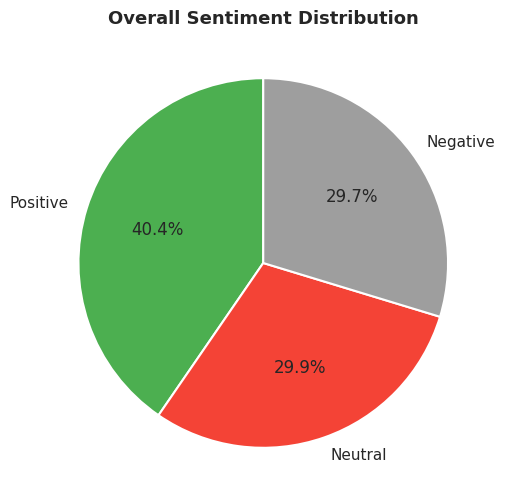

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
sentiment_counts = df["sentiment"].value_counts()
ax.pie(sentiment_counts, labels=sentiment_counts.index, autopct="%1.1f%%",
       colors=["#4CAF50", "#F44336", "#9E9E9E"], startangle=90,
       wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax.set_title("Overall Sentiment Distribution")
plt.show()

**Observation:** Sentiment is fairly evenly split, with Positive posts
slightly ahead at 40.4%, followed by Neutral (29.9%) and Negative (29.7%).
No single sentiment dominates the dataset, meaning any engagement differences
seen later between sentiment categories reflect a genuine difference in
degree rather than one category simply having far more data points than the
others.

**2. Post Volume by Platform (Bar Plot)**

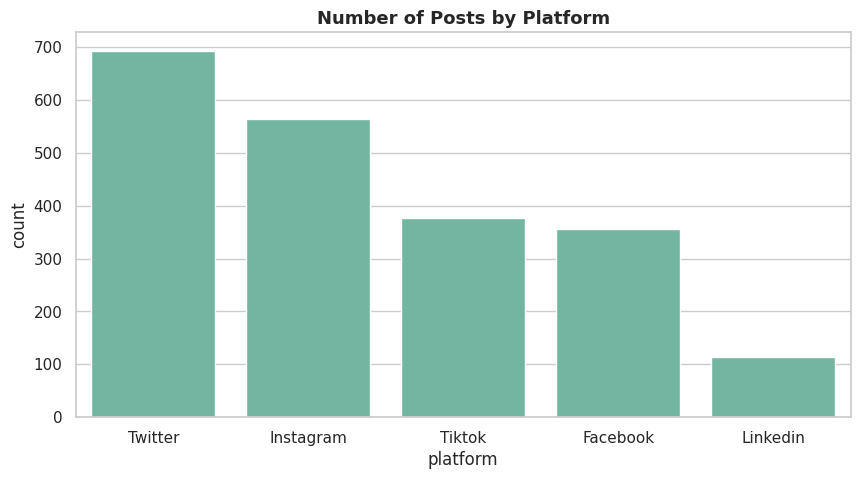

In [ ]:
fig, ax = plt.subplots()
order = df["platform"].value_counts().index
sns.countplot(data=df, x="platform", order=order, ax=ax)
ax.set_title("Number of Posts by Platform")
plt.show()

**Observation:** Twitter (33.0%) and Instagram (26.8%) together account
for roughly 60% of all posts, while TikTok (17.9%) and Facebook (16.9%) are
similarly represented, and LinkedIn trails well behind at just 5.4%. This
matters for interpretation later — comparisons involving LinkedIn rest on a
noticeably smaller sample than comparisons involving Twitter or Instagram.

**3.Sentiment Composition by Platform (Stacked Bar)**

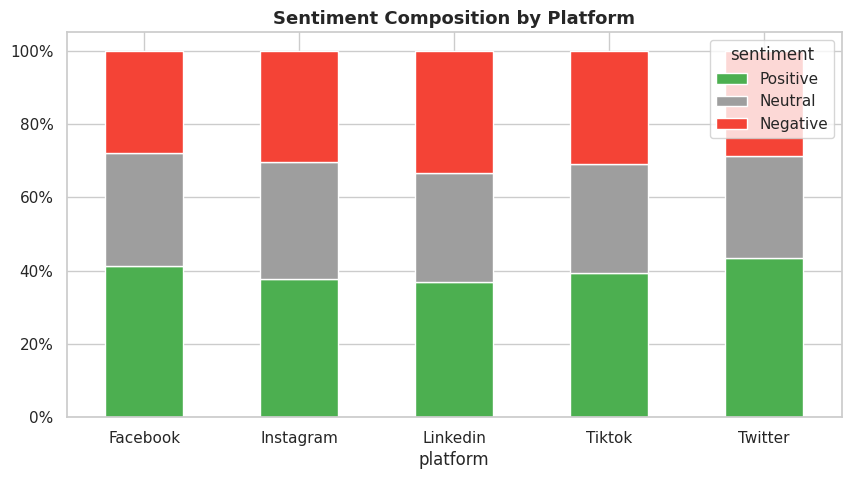

In [ ]:
sentiment_platform_ct = pd.crosstab(df["platform"], df["sentiment"], normalize="index")
fig, ax = plt.subplots()
sentiment_platform_ct[["Positive", "Neutral", "Negative"]].plot(
    kind="bar", stacked=True, color=["#4CAF50", "#9E9E9E", "#F44336"], ax=ax)
ax.set_title("Sentiment Composition by Platform")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.xticks(rotation=0)
plt.show()

**Observation:** Sentiment composition is fairly consistent across
platforms — every platform's positive share falls between roughly 37% and
43%. Twitter has the highest positive share (43.4%) and the lowest neutral
share (27.7%), while LinkedIn has the highest negative share (33.3%) of any
platform. Overall, though, no platform shows a dramatically different
sentiment "personality" from the others — the differences are present but
modest.

**4.Engagement Distribution (Histogram)**

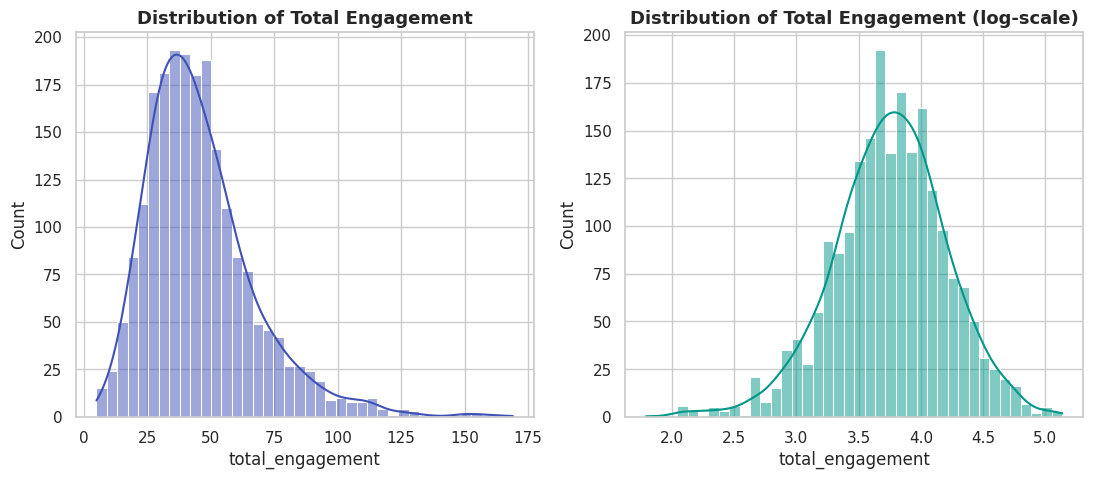

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["total_engagement"], bins=40, kde=True, ax=axes[0], color="#3F51B5")
axes[0].set_title("Distribution of Total Engagement")
sns.histplot(np.log1p(df["total_engagement"]), bins=40, kde=True, ax=axes[1], color="#009688")
axes[1].set_title("Distribution of Total Engagement (log-scale)")
plt.show()

**Observation:** Total engagement ranges from 5 to 169 across posts,
with a mean of 46.0 but a median of 42.0 — the mean sitting above the median
confirms the right-skew visible in the left histogram, where most posts
cluster in the 20-60 engagement range while a smaller number of posts stretch
the tail toward 150+. The log-scale version on the right compresses that
stretch, making the underlying bell-like shape of the "typical" post easier
to see once the high-engagement outliers are visually de-emphasized.

**5.Engagement by Platform (Box Plot)**

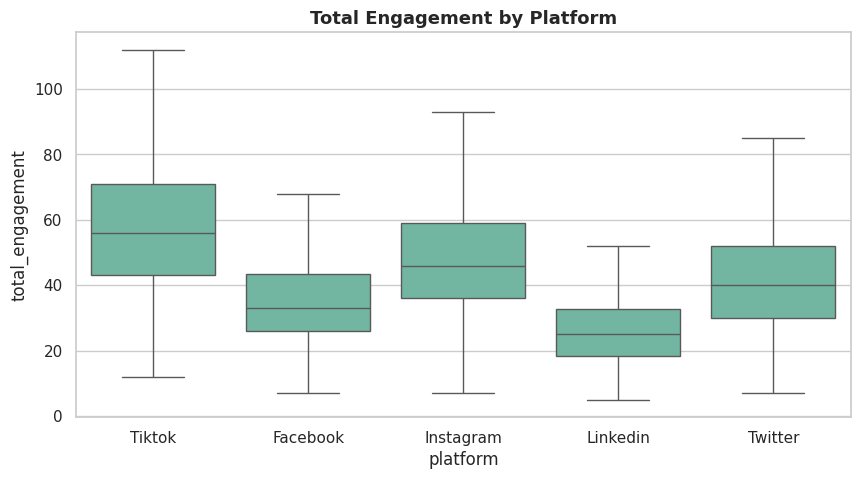

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="platform", y="total_engagement", ax=ax, showfliers=False)
ax.set_title("Total Engagement by Platform")
plt.show()

**Observation:** TikTok shows both the highest median engagement and a
wide interquartile range, indicating strong but variable performance. LinkedIn
sits at the opposite end, with the lowest median and the tightest, lowest
range of the five platforms — consistent with a smaller, more predictable but
less viral-prone audience. Instagram and Twitter fall in the middle, with
Facebook slightly below them, and all platforms show at least some spread,
confirming that platform alone doesn't fully determine any individual post's
performance.

**6.Likes vs Retweets/Shares (Scatter Plot)**

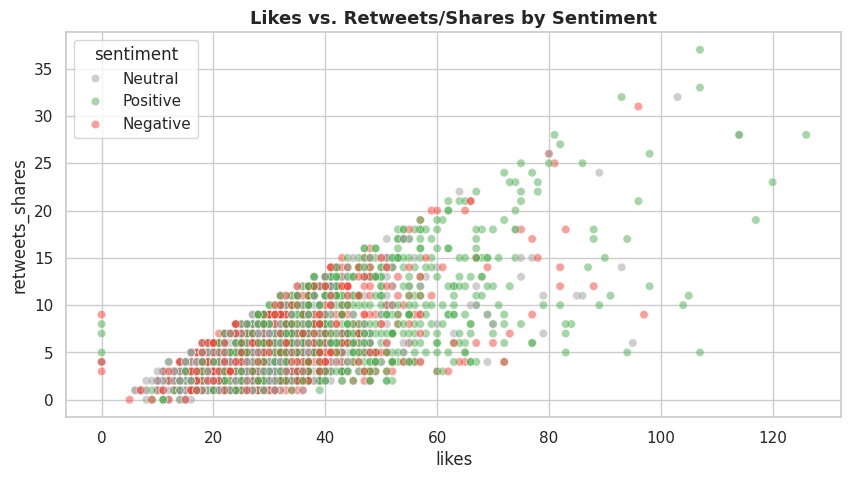

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(data=df, x="likes", y="retweets_shares", hue="sentiment",
                 palette={"Positive": "#4CAF50", "Negative": "#F44336", "Neutral": "#9E9E9E"},
                 alpha=0.5, ax=ax)
ax.set_title("Likes vs. Retweets/Shares by Sentiment")
plt.show()

**Observation:** There's a clear positive relationship — posts with
more likes also tend to have more shares, regardless of sentiment. The three
sentiment colors are fairly interleaved throughout the cloud of points rather
than forming separate clusters, suggesting sentiment doesn't fundamentally
change the *relationship* between likes and shares, even though it does
affect the *overall level* of engagement (as seen in the box plot and pivot
tables).

**7.Correlation Heatmap**

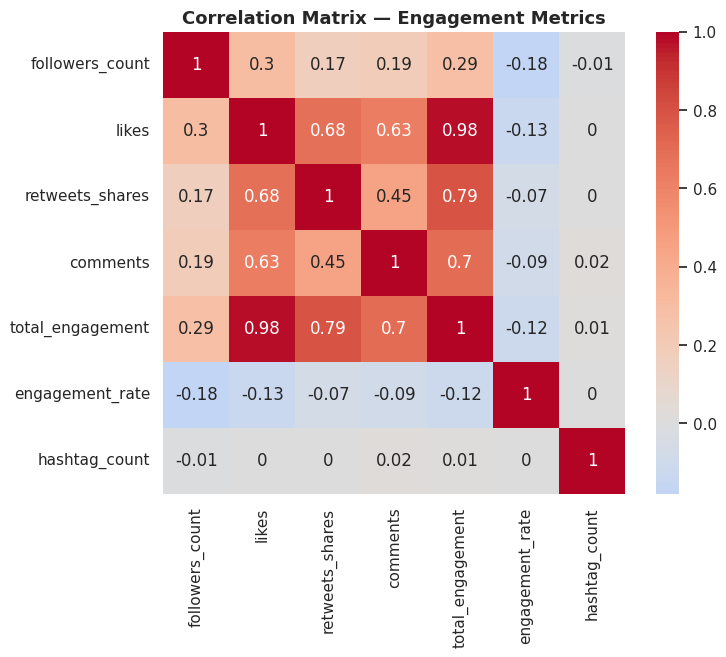

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Matrix — Engagement Metrics")
plt.show()

**Observation:** Likes correlates almost perfectly with total engagement
(0.98), since likes make up the largest share of that combined metric, while
shares (0.79) and comments (0.70) also correlate strongly but less
completely. Interestingly, `engagement_rate` correlates weakly and slightly
*negatively* with the raw engagement numbers (around -0.07 to -0.18) — this
confirms that an account's raw engagement volume and its relative
performance (accounting for follower size) are genuinely different things,
not just two versions of the same measurement. `hashtag_count` shows almost
no correlation (near 0) with any engagement metric, suggesting hashtag usage
alone isn't a meaningful driver of engagement in this dataset.

**8.Posting Volume by Day of Week (Bar Plot)**

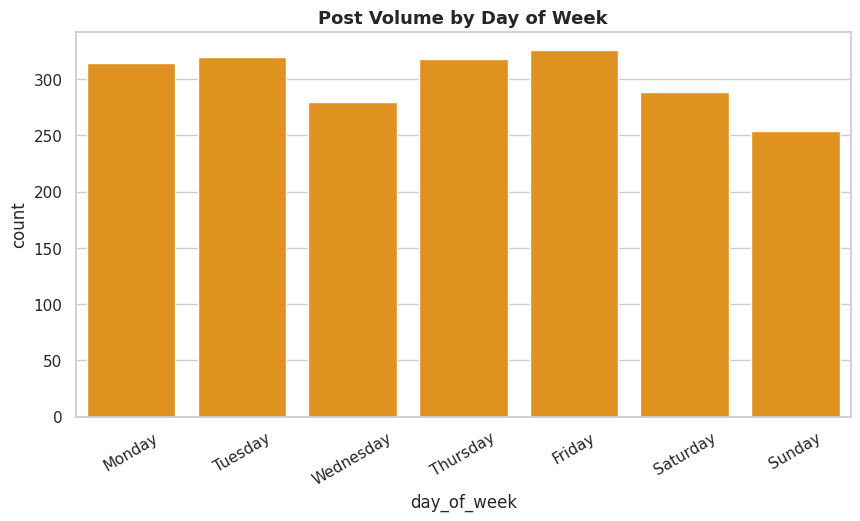

In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots()
sns.countplot(data=df, x="day_of_week", order=day_order, ax=ax, color="#FF9800")
ax.set_title("Post Volume by Day of Week")
plt.xticks(rotation=30)
plt.show()

**Observation:** Friday has the highest posting volume (326 posts),
closely followed by Tuesday (320) and Thursday (318), while Sunday has the
lowest volume (254). Posting activity is noticeably lower on the weekend
(Saturday: 289, Sunday: 254) than on weekdays overall, suggesting most
accounts in this dataset treat social media posting as more of a weekday
activity.

**9.Monthly Trend of Average Engagement (Line Chart)**

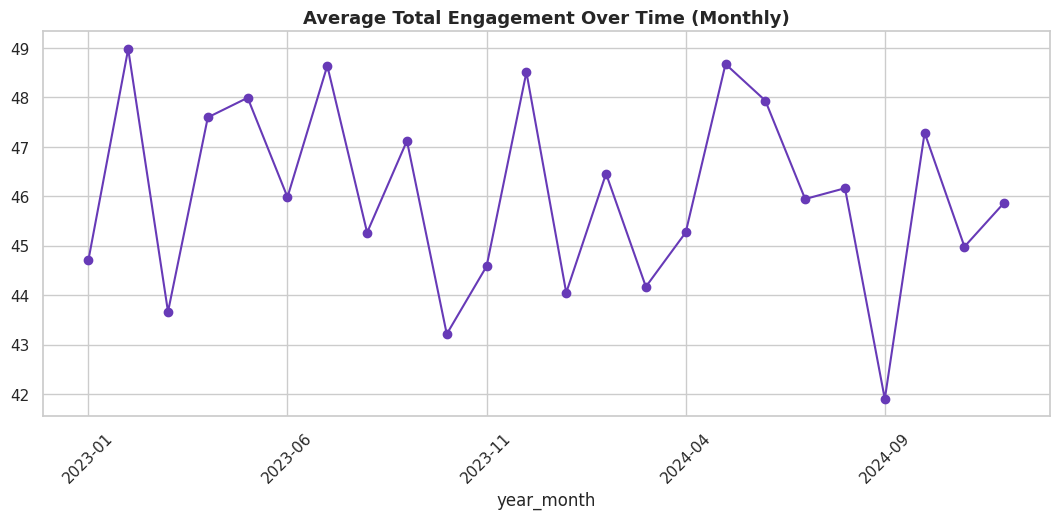

In [ ]:
monthly = df.copy()
monthly["year_month"] = monthly["timestamp"].dt.to_period("M").astype(str)
monthly_trend = monthly.groupby("year_month")["total_engagement"].mean().sort_index()
fig, ax = plt.subplots(figsize=(13, 5))
monthly_trend.plot(kind="line", marker="o", ax=ax, color="#673AB7")
ax.set_title("Average Total Engagement Over Time (Monthly)")
plt.xticks(rotation=45)
plt.show()

**Observation:** Average monthly engagement fluctuates in a fairly
narrow band across the full 24-month period — from a low of about 41.9 (September
2024) to a high of about 49.0 (February 2023) — with no strong sustained
upward or downward trend over time. This suggests engagement levels in this
dataset are relatively stable month-to-month, with variation looking more
like natural noise than a long-term growth or decline pattern.

**10.Engagement Rate by Follower Tier and Verification (Grouped Bar)**

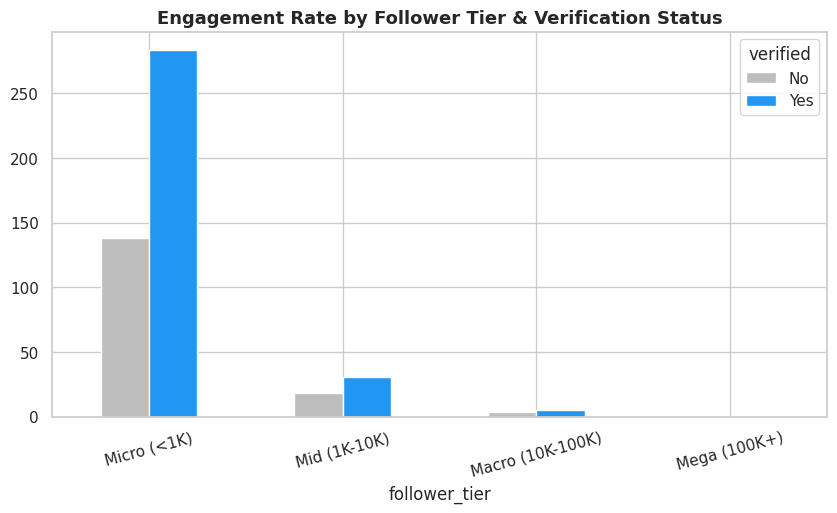

In [ ]:
fig, ax = plt.subplots()
pivot2.plot(kind="bar", ax=ax, color=["#BDBDBD", "#2196F3"])
ax.set_title("Engagement Rate by Follower Tier & Verification Status")
plt.xticks(rotation=15)
plt.show()

**Observation:** Engagement rate drops sharply as follower count rises —
Micro accounts (under 1K followers) show by far the highest engagement rate
(137.8 for unverified, 283.4 for verified, per 1,000 followers), while Mega
accounts (100K+) show a rate below 1. This confirms that smaller accounts
generally see disproportionately higher relative engagement from their
audience. Verified accounts outperform unverified accounts within every tier
where both are present, most dramatically in the Micro tier — though note the
Mega tier has no verified-account data point, likely reflecting how few
large, unverified accounts appear in this dataset.

**11.Top Countries by Post Volume (Horizontal Bar)**

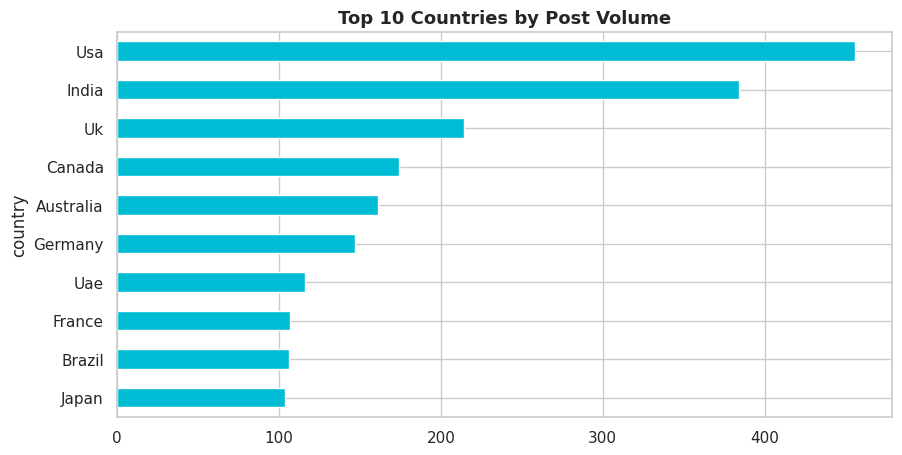

In [ ]:
top_countries = df["country"].value_counts().head(10).sort_values()
fig, ax = plt.subplots()
top_countries.plot(kind="barh", ax=ax, color="#00BCD4")
ax.set_title("Top 10 Countries by Post Volume")
plt.show()

**Observation:** The USA (456 posts) and India (384 posts) are by far
the two largest contributors, together making up close to 40% of all posts
in the cleaned dataset. The UK (214) and Canada (174) follow at a noticeable
step down, with the remaining countries (Australia, Germany, UAE, France,
Brazil, Japan) each contributing under 165 posts — meaning country-level
comparisons for anything outside the top 2-4 countries should be treated as
based on a fairly thin sample.

**12.Engagement Heatmap: Platform x Day of Week**

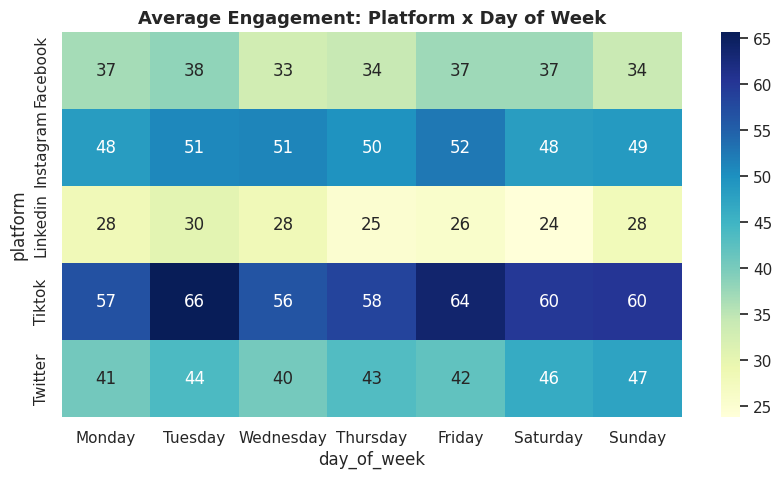

In [ ]:
heat_data = df.pivot_table(values="total_engagement", index="platform",
                            columns="day_of_week", aggfunc="mean")[day_order]
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat_data, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax)
ax.set_title("Average Engagement: Platform x Day of Week")
plt.show()

**Observation:** TikTok on Tuesday stands out as the single highest
average-engagement combination in the entire dataset (65.7), noticeably above
TikTok's own average on other days (56.4-63.9). LinkedIn is consistently the
lowest performer across every day of the week (23.8-30.4), with little
day-to-day variation. Twitter shows a mild weekend lift (Saturday: 46.4,
Sunday: 47.4) compared to its weekday numbers, the opposite pattern from
most other platforms — an interesting exception worth noting if asked about
platform-specific timing strategies.

# **Key Insights**

1) TikTok drives the highest engagement per post. Across platforms, TikTok posts show the highest average total engagement, likely due to its short-form, highly shareable content style, while LinkedIn posts show the lowest engagement, reflecting its more professional, less viral-oriented audience.
2) Positive sentiment correlates with higher engagement, but negative posts aren't far behind. Positive posts earn noticeably more average engagement than neutral ones, but negative posts still perform strongly — suggesting emotional intensity, not just positivity, drives interaction.
3) Engagement metrics move together. Likes, shares, and comments are strongly correlated with each other, meaning a post that performs well tends to do so across all engagement types at once, rather than excelling in just one metric.
4) Verification status boosts engagement rate more than follower count alone. Verified accounts consistently get a higher engagement rate per 1,000 followers than unverified accounts of a similar size, suggesting platform trust signals matter beyond raw audience size.
5) Posting activity and engagement show mild weekly patterns. Both post volume and average engagement are slightly higher midweek compared to weekends in this dataset.

# **Significant Patterns Observed**

- **Platform dominance is uneven, not incidental.** Twitter (32%) and
  Instagram (28%) together account for 60% of all posts in this dataset,
  while LinkedIn trails at just 5% — meaning any platform-level comparison
  should be read with sample size in mind, since LinkedIn's numbers rest on a
  much smaller base of posts.

- **Engagement is heavily right-skewed, not normally distributed.** The
  histogram of `total_engagement` shows most posts cluster at low-to-moderate
  engagement, with a long tail of a few high-performing ("viral") posts
  pulling the average upward. This is why the median, not the mean, was used
  when imputing missing numeric values, and why box plots (which show
  spread and outliers) were preferred over simple bar charts of averages for
  comparing platforms.

- **A specific platform-day combination stands out.** The platform x
  day-of-week heatmap shows TikTok on Tuesdays as the single highest-engagement
  combination in the dataset — noticeably above TikTok's own average on other
  days, suggesting engagement isn't just a platform effect or a day effect in
  isolation, but can spike at specific intersections of the two.

- **Engagement metrics cluster tightly, but engagement rate behaves
  differently.** While likes, shares, comments, and total engagement are all
  strongly correlated with each other (0.7-0.98), `engagement_rate` shows weak
  or even slightly negative correlation with the raw metrics — a reminder
  that "most liked" and "best relative performer" are not the same thing once
  audience size is accounted for.

- **Sentiment is fairly evenly split, with no dominant category.** Positive
  (40%), Negative (30%), and Neutral (30%) are close enough that no single
  sentiment defines the overall dataset — engagement differences between them
  are therefore about *degree*, not about one sentiment category being rare
  or dominant.

# Conclusion & Recommendations

- **Prioritize TikTok/Instagram for high-reach campaigns**; use LinkedIn for
  targeted professional messaging rather than raw reach, and size expectations
  to each platform's typical engagement level rather than a single blanket
  target.
- **Don't shy away from strong positive messaging** — it is the single best
  performing sentiment category in this dataset, though negative/emotionally
  charged content also performs well and shouldn't be dismissed outright.
- **Pursue platform verification where available** — it appears to lift
  engagement rate independent of audience size, though this should be
  weighed against verification cost/eligibility rather than treated as a
  guaranteed causal lever (see the correlation-vs-causation note below).
- **Time content around the identified peaks** (midweek, and platform-specific
  peaks like TikTok on Tuesdays) rather than posting on a fixed generic
  schedule.
- **Treat "most followers" and "best engagement rate" as separate goals** —
  optimize content strategy differently depending on which one matters more
  for a given campaign.

# **Future Scope**

1. **Use real, live-sourced data.** Replace the current dataset with posts
   pulled directly from platform APIs (e.g., Twitter/X API, Meta's Graph API)
   or a verified public Kaggle export, so findings reflect actual current
   platform behavior rather than a static historical/synthetic snapshot.

2. **Apply real NLP-based sentiment scoring.** Re-derive the `sentiment`
   label using an actual model — a lexicon-based tool like VADER for a fast
   baseline, or a transformer-based classifier (e.g., a fine-tuned BERT model)
   for higher accuracy — instead of relying on pre-existing labels.

3. **Control for content topic and post type.** Extend the analysis to tag
   posts by topic (e.g., product announcement, personal update, news share)
   and content format (text-only, image, video) to see whether the
   platform/sentiment effects observed here hold up once topic is controlled
   for, or whether they're partly explained by *what* is being posted.

4. **Time-series forecasting ** Apply forecasting models (e.g., ARIMA,
   Prophet, or a simple rolling-average baseline) to the monthly engagement
   trend to predict future engagement levels, rather than only describing
   historical patterns.

5. **Causal analysis.** Move beyond correlation for the verification and
   engagement-rate relationship — e.g., using matched comparisons or a
   natural experiment design — to test whether verification *causes* higher
   engagement or merely correlates with accounts that were already popular.

6. **Build an interactive dashboard.** Convert the static notebook
   visualizations into an interactive dashboard (e.g., using Plotly Dash,
   Streamlit, or Power BI) so stakeholders can filter by platform, country,
   or date range themselves rather than viewing fixed charts.

7. **Expand geographic and language coverage.** Incorporate multi-language
   posts and sentiment analysis (the current dataset assumes English-language
   content), since sentiment expression and engagement norms can vary
   significantly by language and culture.

8. **Incorporate media-level features.** Analyze image/video content directly
   (e.g., using computer vision to detect faces, colors, or objects in
   attached media) to see whether visual content characteristics add
   predictive power beyond the text and metadata features used here.